In [1]:
!git clone https://github.com/alessiobsc/GenerativeAI---Face-Generation-on-CelebA.git
!pip -q install gdown


Cloning into 'GenerativeAI---Face-Generation-on-CelebA'...
remote: Enumerating objects: 70, done.
remote: Counting objects: 100% (70/70), done.
remote: Compressing objects: 100% (58/58), done.
remote: Total 70 (delta 24), reused 53 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (70/70), 1.58 MiB | 28.82 MiB/s, done.
Resolving deltas: 100% (24/24), done.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:


checkpoint_path = "/content/drive/MyDrive/Generative AI Project/vae/weights/cvae_weights_epoch83.ckp"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CVAE(input_channel=3, latent_dim=128, num_cond=3).to(device)

checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model"])

model.eval()

CVAE(
  (encoder): Sequential(
    (0): Conv2d(6, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2, inplace=True)
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.2, inplace=True)
    (9): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.2, inplace=True)
  )
  (fc_mu): Linear(in_features=4096, out_features=128, bias=True)
  (fc_logvar): Linear(in_f

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CVAE(input_channel=3, latent_dim=128, num_cond=3).to(device)
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model"] if "model" in checkpoint else checkpoint)
model.eval()


CVAE(
  (encoder): Sequential(
    (0): Conv2d(6, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2, inplace=True)
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.2, inplace=True)
    (9): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.2, inplace=True)
  )
  (fc_mu): Linear(in_features=4096, out_features=128, bias=True)
  (fc_logvar): Linear(in_f

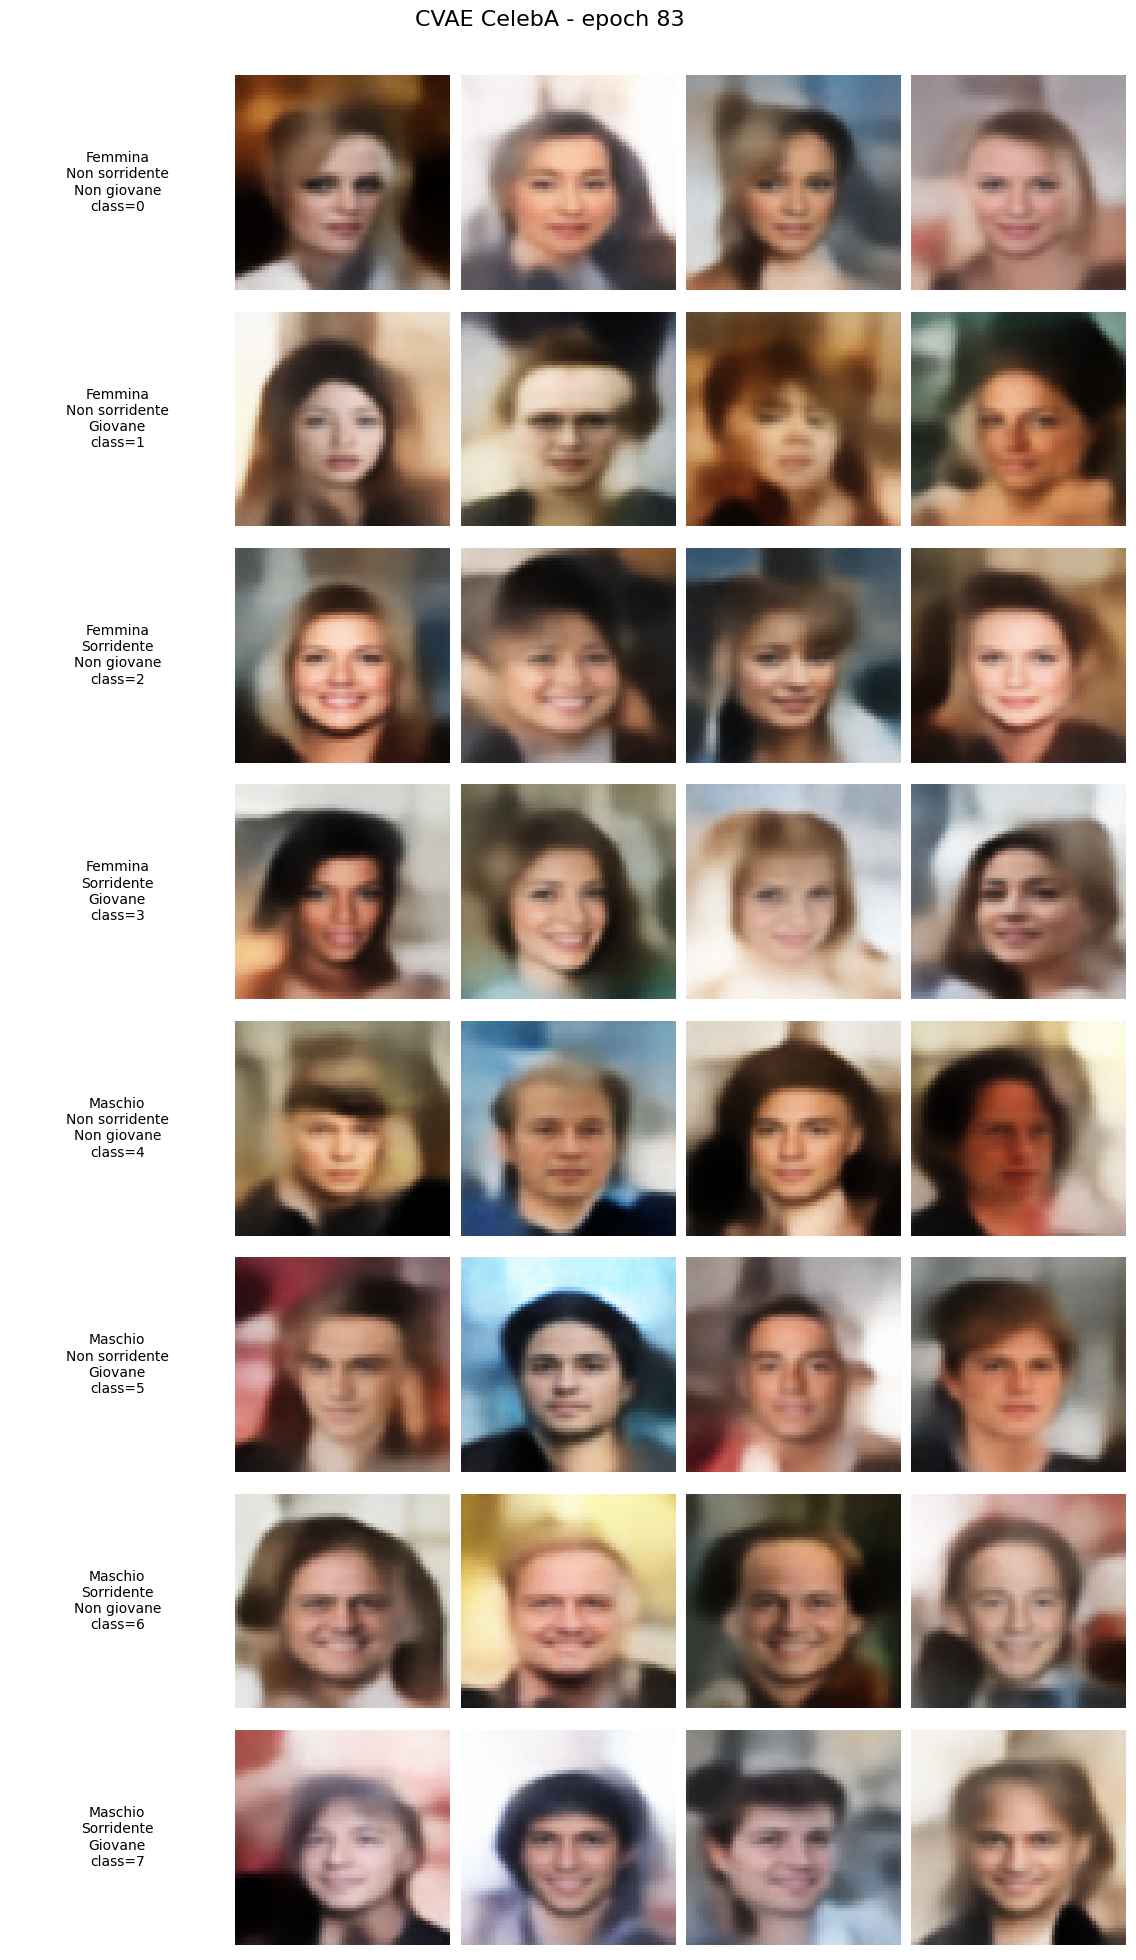

In [9]:
conditions = [
    (0, 0, 0), (0, 0, 1), (0, 1, 0), (0, 1, 1),
    (1, 0, 0), (1, 0, 1), (1, 1, 0), (1, 1, 1)
]

fig, axes = plt.subplots(8, 5, figsize=(12, 20))
fig.suptitle("CVAE CelebA - epoch 83", fontsize=16)

with torch.no_grad():
    for i, (male, smiling, young) in enumerate(conditions):
        label = f"{'Maschio' if male else 'Femmina'}\n{'Sorridente' if smiling else 'Non sorridente'}\n{'Giovane' if young else 'Non giovane'}\nclass={i}"
        axes[i, 0].text(0.5, 0.5, label, ha="center", va="center", fontsize=10)
        axes[i, 0].axis("off")
        cond = torch.tensor([[male, smiling, young]], dtype=torch.float32, device=device).repeat(4, 1)
        imgs = ((model.generate(cond, device=device) + 1) / 2).clamp(0, 1).cpu().numpy()
        for j in range(4):
            axes[i, j + 1].imshow(np.transpose(imgs[j], (1, 2, 0)))
            axes[i, j + 1].axis("off")

plt.subplots_adjust(wspace=0.05, hspace=0.05, top=0.95, bottom=0.01, left=0.05, right=0.98)
plt.savefig("cvae_generation_grid.png", dpi=200, bbox_inches="tight")
plt.show()
